In [172]:
import random

from numpy.ma.core import argmax
from torchmetrics import ConfusionMatrix
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torchvision
from torch.nn.modules import loss
from torchvision import datasets
from torchvision import transforms
from torchvision.datasets import DatasetFolder
from torchvision.transforms import ToTensor
from torch.utils.data import Dataset, DataLoader
from timeit import default_timer as timer
from tqdm.auto import tqdm
import torchmetrics
import mlxtend
import numpy as np
from torchmetrics import ConfusionMatrix


In [2]:
#DEVICE AGNOSTIC
device = "cuda" if torch.cuda.is_available() else "cpu"

In [3]:
#GETTING THE FOOD DATA AND MAKING THE PATHS AND THIS .....
import requests
import zipfile
from pathlib import Path
#make path
data_path = Path("../data/")
image_path = data_path / "food"
if image_path.is_dir():
    print("it already exists")
else:
    print("doesn't exist , downloading .....")
    image_path.mkdir(parents=True,exist_ok=True)
#makeing the request
with open(data_path / "food.zip" , "wb") as f:
    request = requests.get("https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi.zip")
    print ("the file is downloading ......")
    f.write(request.content)
#unzipping
with zipfile.ZipFile(data_path / "food.zip","r") as zip_ref:
    print("unzipping ......")
    zip_ref.extractall(image_path)


it already exists
the file is downloading ......
unzipping ......


In [4]:
#MAKE A WALK THROUGH THE DATA FUNCTION
import os
def walk_data (path):
    for i , j, k in os.walk(path):
        print(f"there are {len(j)} directories and {len(k)} images in {len(i)}")

walk_data(image_path)

there are 2 directories and 0 images in 9
there are 3 directories and 0 images in 14
there are 0 directories and 25 images in 20
there are 0 directories and 19 images in 20
there are 0 directories and 31 images in 20
there are 3 directories and 0 images in 15
there are 0 directories and 78 images in 21
there are 0 directories and 75 images in 21
there are 0 directories and 72 images in 21


In [5]:
#MAKE THE TRAINING AND TESTING PATH
train_dir = image_path / "train"
test_dir = image_path / "test"

path: data\food\train\sushi\170385.jpg
class: sushi


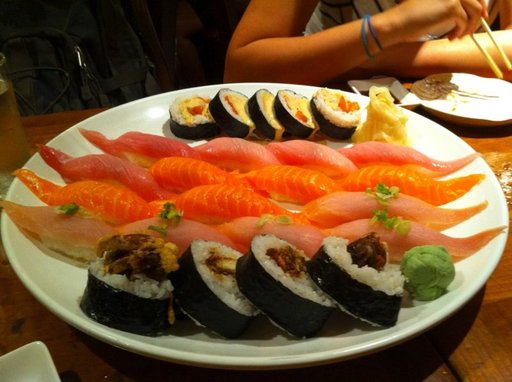

In [39]:
#MAKE SOME VISUALIZATION AND LOOKING AT A RANDOM IMAGE
from PIL import Image
import random
#get image paths
image_paths_list = list(image_path.glob("*/*/*.jpg"))
#random
random_image_path = random.choice(image_paths_list)
#get class
random_image_class=random_image_path.parent.stem
#open
open_img =Image.open(random_image_path)

print(f"path: {random_image_path}")
print(f"class: {random_image_class}")
open_img

In [7]:
open_img.size

(512, 512)

# MAKE DATA USING LIBRARIES

In [8]:
# TRANSFORMS : MAKE THE IMAGE/IMAGES ->TENSOR / AND RESHAPE SIZE USING THE  TRANSFORM, FLIP IMAGES RANDOMLY ON THE HORIZ.
from torchvision import transforms
data_transform = transforms.Compose([
    transforms.Resize(size=(64,64)),
    transforms.RandomHorizontalFlip(0.5),
    transforms.ToTensor(),
])

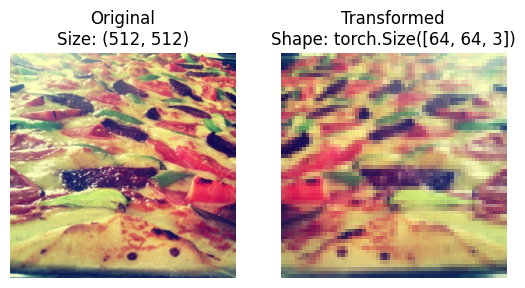

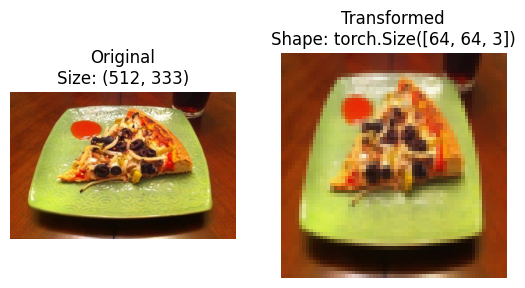

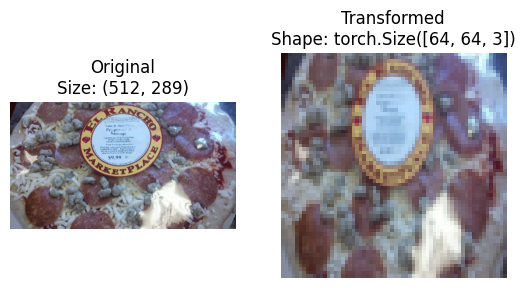

In [37]:
#OPTIONAL : MAKE A FUN THAT TAKES A RANDOM, IMAGES AND TRANSFORM IT AND THEN MAKE A COMPARISON BETWEEN THE 2
def comparer (image_paths_list = image_paths_list,
              transform = data_transform,
              n=3):
    random_image_path = random.sample(image_paths_list, k=n)
    for image_path in random_image_path:
        with Image.open(image_path) as img:
            fig, ax = plt.subplots(nrows=1, ncols=2)
            ax[0].imshow(img)
            ax[0].set_title(f"Original\nSize: {img.size}")
            ax[0].axis(False)

            # Transform and plot target image
            transformed_image = transform(img).permute(1, 2, 0)
            ax[1].imshow(transformed_image)
            ax[1].set_title(f"Transformed\nShape: {transformed_image.shape}")
            ax[1].axis("off")


comparer()



In [10]:
#LOADNG DATA USING (IMAGE FOLDER)
train_data = datasets.ImageFolder(root = train_dir
                                 ,transform=data_transform,
                                  target_transform=None)
test_data = datasets.ImageFolder(root =test_dir,
                                 transform=data_transform,)
train_data , test_data

(Dataset ImageFolder
     Number of datapoints: 225
     Root location: data\food\train
     StandardTransform
 Transform: Compose(
                Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
                RandomHorizontalFlip(p=0.5)
                ToTensor()
            ),
 Dataset ImageFolder
     Number of datapoints: 75
     Root location: data\food\test
     StandardTransform
 Transform: Compose(
                Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
                RandomHorizontalFlip(p=0.5)
                ToTensor()
            ))

In [11]:

#get class names as list
class_names = train_data.classes
#get class names a dictionary
class_dic = train_data.class_to_idx

class_names , class_dic

(['pizza', 'steak', 'sushi'], {'pizza': 0, 'steak': 1, 'sushi': 2})

In [12]:
train_data[0][0].shape,train_data[0][1]

(torch.Size([3, 64, 64]), 0)

In [13]:
#see the cpu number
os.cpu_count()

16

In [14]:
#MAKE IMAGES IN BATCHES USING THE DATA LOADER
NUM_WORKERS = os.cpu_count()
BATCH_SIZE = 16
train_dataloader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)
test_dataloader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

print(f"number batches: {len(train_dataloader) , len(test_dataloader)}")

number batches: (15, 5)


In [15]:
#check the classes and the classes to index on our Data
img , label = next(iter(train_dataloader))
print(f"images per batch : {img.shape}")
print(f"label : {label.shape}")
print(f"label : {label}")

images per batch : torch.Size([16, 3, 64, 64])
label : torch.Size([16])
label : tensor([1, 0, 0, 2, 2, 1, 0, 0, 2, 0, 0, 0, 2, 0, 1, 0])


# MAKING CUSTOM_DATA



In [16]:
#making the imports
import os
import pathlib
import torch
from PIL import Image
from torch.utils.data import Dataset
from torchvision import transforms
from typing import Tuple, Dict, List

In [41]:
#create a helper functions to see the class names(the function that get us (list/dic) of the Data classes using the os.scandir for this

def find_classes (target_directory):
    """get names of all classes in a directory"""
    classes = sorted(entry.name for entry in os.scandir(target_directory) if entry.is_dir())

    #raise an error if the class is not found (RAISE:THROUGH AN ERROR AND STOP THE PROGRAM COMPLETELY )
    if not classes:
        raise FileNotFoundError (f"no classes found in {target_directory}...... so please check the files")

    classes_to_idx = {class_name : i for i, class_name in enumerate(classes)}
    return classes , classes_to_idx


#try it on our Data
class_list_try , class_dic_try = find_classes(train_dir)
class_dic_try , class_list_try

({'pizza': 0, 'steak': 1, 'sushi': 2}, ['pizza', 'steak', 'sushi'])

In [40]:
#this is what enumerate does
l = ["d","f","t"]
for i in enumerate(l):
    print(i)

(0, 'd')
(1, 'f')
(2, 't')


In [49]:
#making the custom dataset that replicates the (image folder)
class custom_image_folder (Dataset):
    #MAKE THE SELF CHARS FUNCTION
    def __init__ (self , target_dir , transform = None):
        self.path = list(pathlib.Path(target_dir).glob('*/*.jpg'))
        self.transform = transform
        self.classes , self.classes_to_idx  = find_classes (target_dir)  #this is the function that we have created

    #THIS IS TO LOAD IMG
    def load_image (self , index):
        image_path = self.path[index]
        image = Image.open(image_path)
        return image

    #TO GET LENGTH
    def __len__ (self):
        return len(self.path)

    #TO GET A SPECIFIC SAMPLE IN FORM OF (DATA , LABEL)
    def __getitem__(self, index):
        img = Image.open(self.path[index]) #we can also make it by the function we made--> self.load_image(index)
        class_name = self.path[index].parent.name # expects path in format--> data_folder/class_name/image.jpg
        class_index = self.classes_to_idx[class_name]
        #transform if nessesary
        if self.transform:
            return self.transform(img), class_index
        else:
            return img,class_index



remember:





    def __init__(self):        # Special! Called when creating object
        pass

    def __len__(self):         # Special! Called by len()
        pass

    def __getitem__(self, i):  # Special! Called by []
        pass


225
(tensor([[[0.1137, 0.1020, 0.0980,  ..., 0.1255, 0.1216, 0.1176],
         [0.1059, 0.0980, 0.0980,  ..., 0.1294, 0.1294, 0.1294],
         [0.1020, 0.0980, 0.0941,  ..., 0.1333, 0.1333, 0.1333],
         ...,
         [0.1098, 0.1098, 0.1255,  ..., 0.1686, 0.1647, 0.1686],
         [0.0902, 0.0941, 0.1098,  ..., 0.1686, 0.1647, 0.1686],
         [0.0863, 0.0863, 0.0980,  ..., 0.1686, 0.1647, 0.1647]],

        [[0.0745, 0.0706, 0.0745,  ..., 0.0588, 0.0588, 0.0588],
         [0.0745, 0.0706, 0.0745,  ..., 0.0627, 0.0627, 0.0627],
         [0.0706, 0.0745, 0.0745,  ..., 0.0706, 0.0706, 0.0706],
         ...,
         [0.1255, 0.1333, 0.1373,  ..., 0.2510, 0.2392, 0.2392],
         [0.1098, 0.1176, 0.1255,  ..., 0.2510, 0.2392, 0.2314],
         [0.1020, 0.1059, 0.1137,  ..., 0.2431, 0.2353, 0.2275]],

        [[0.0941, 0.0902, 0.0902,  ..., 0.0157, 0.0196, 0.0196],
         [0.0902, 0.0863, 0.0902,  ..., 0.0196, 0.0157, 0.0196],
         [0.0902, 0.0902, 0.0902,  ..., 0.0157, 0.015

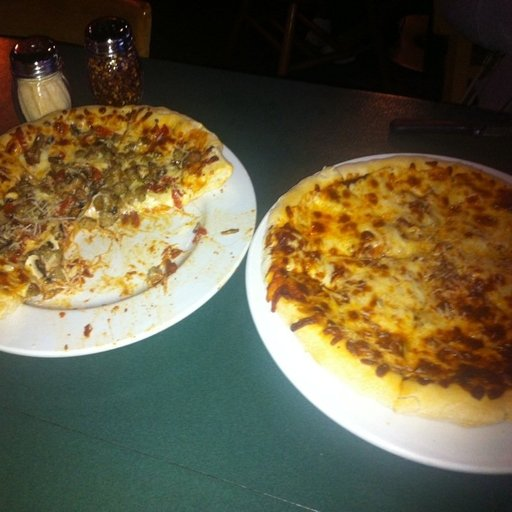

In [89]:
#try the custom image folder
custom_train_data = custom_image_folder(train_dir,
                                        data_transform) # this is the transform function that we made earlier
custom_test_data = custom_image_folder(test_dir,
                                       data_transform)
#1
print(len(custom_train_data))
#2
print(custom_train_data[0])
#3
custom_train_data.load_image(0)

In [90]:
#compare custom with library
print(len(train_data) == len(custom_train_data))
print(train_data.classes == custom_train_data.classes)



True
True


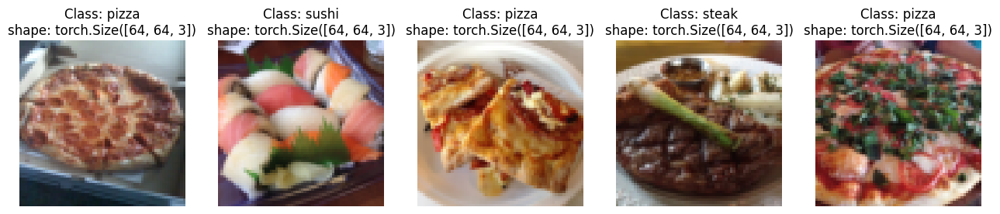

In [104]:
#make a function that shows random images [max 10]
def random_image_displayer (dataset,
                            classes,
                            n,
                            display_shape = True):
    #check if more than 10
    if n>10:
        n=10
        print("what is all of this images , we make it 10 ")

    #take random indicies
    random_indicies = random.sample(range(len(dataset)), n)

    # set up the plot
    plt.figure(figsize=(16,8))

    #here we are going to use the enumertate because we are gouing to use the i in the plot numbering
    for i , target_sample in enumerate(random_indicies):
        target_image , targ_label = dataset[target_sample][0], dataset[target_sample][1]
        targ_image_adjust = target_image.permute(1, 2, 0)

         # Plot adjusted samples
        plt.subplot(1, n, i+1)
        plt.imshow(targ_image_adjust)
        plt.axis("off")
        if classes:
          title = f"Class: {classes[targ_label]}"
          if display_shape:
            title = title + f"\nshape: {targ_image_adjust.shape}"
        plt.title(title)

random_image_displayer (custom_train_data,n=5,classes = class_names)


In [105]:
#USE THE DATALOADER
train_dataloader_custom = DataLoader(custom_train_data, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)
test_dataloader_custom =  DataLoader(custom_test_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

# PLAY WITH DATA AUGMENTATION

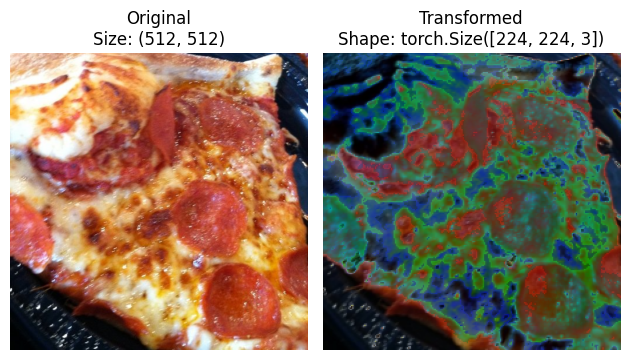

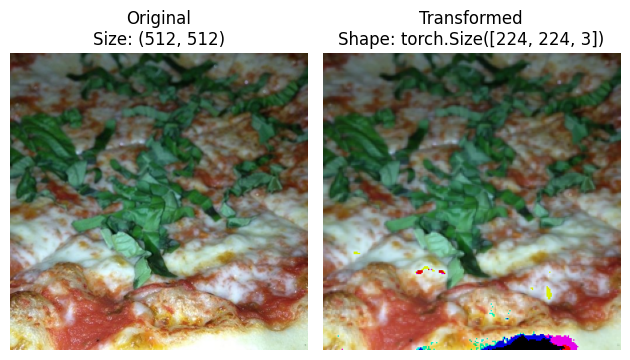

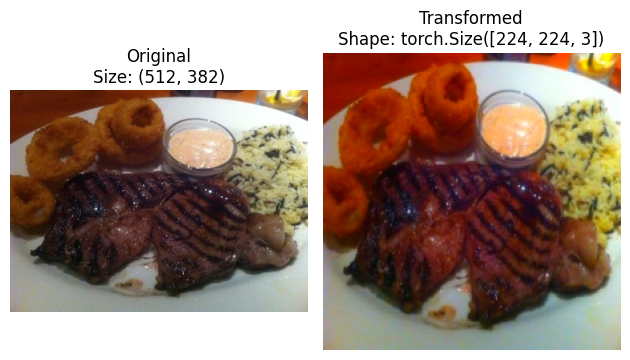

In [140]:
#this is just it add the augmentation that we want to use
train_transform = transforms.Compose([
                                      transforms.Resize(size=(224, 224)),
                                      transforms.TrivialAugmentWide(num_magnitude_bins=31),
                                      transforms.ToTensor()
])

#use the comparer function (we made a default Data)
comparer(transform = train_transform)

# MAKE MODEL

In [142]:
#MAKE SOME SIMPLE DATA
#make trans
simple_transform = transforms.Compose([
    transforms.Resize(size=(64, 64)),
    transforms.ToTensor()
])
#img folder
simple_train_data = datasets.ImageFolder(train_dir, transform = simple_transform)
simple_test_data = datasets.ImageFolder(test_dir, transform = simple_transform)

#dataloader
BATCH_SIZE = 32
NUM_WORKERS = os.cpu_count()

simple_train_dataloader = DataLoader(simple_train_data, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)
simple_test_dataloader = DataLoader(simple_test_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)


In [158]:
#MAKE THE MODEL
class VGGmodel (nn.Module):
    def __init__(self,
                 input_layers,
                 hidden_layers,
                 output_layers):
        super(VGGmodel, self).__init__()
        self.B1 = nn.Sequential(
            nn.Conv2d(in_channels = input_layers, out_channels = hidden_layers, kernel_size = 3,stride=1, padding = 0),
            nn.ReLU(),
            nn.Conv2d(in_channels = hidden_layers, out_channels = hidden_layers, kernel_size = 3,stride=1, padding = 0),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2,
                     stride=2)
        )
        self.B2 = nn.Sequential(
            nn.Conv2d(in_channels = hidden_layers, out_channels = hidden_layers, kernel_size = 3,stride=1, padding = 0),
            nn.ReLU(),
            nn.Conv2d(in_channels = hidden_layers, out_channels = hidden_layers, kernel_size = 3,stride=1, padding = 0),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2,
                     stride=2)
        )

        self.classifier =nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features = hidden_layers*13*13
                      , out_features = output_layers),
        )

    def forward (self,x):
        return self.classifier(self.B2(self.B1(x)))

In [159]:
#INTIATE THE MODEL
model_4  = VGGmodel(3,64,len(class_names)).to(device)  #len(class_names)---> 3 (pizza,steak,sushi)

In [153]:
#making a foreward pass to see how to fix dimension in the after flatter layer (we are making it using a batch because the conv2D ad maxpool2d are made to be operating in batched for more efficiency , so we are making a single batch)[dim--> [number images in batch(32) , color channels(3) , 64, 64)
image_batch, label_batch = next(iter(simple_train_dataloader))
model_4(image_batch.to(device))

RuntimeError: mat1 and mat2 shapes cannot be multiplied (32x10816 and 64x3)

In [154]:
#making a forward pass to see how to fix dimension in the after flatter layer (this is making unsqueeze for a single image to get that extra dimension of the batch)
model_4(simple_train_data[0][0].unsqueeze(dim=0).to(device))

RuntimeError: mat1 and mat2 shapes cannot be multiplied (1x10816 and 64x3)

In [164]:
#use the torch info to see the details of the 09_EFFICIENTNETB2_MODEL_TRAINED_10EPOCHES_20%PERCENT.pth
try:
    import torchinfo
except ImportError:
    !pip install torchinfo
    import torchinfo
from torchinfo import summary
summary(model_4, input_size=(1,3, 64, 64))



Layer (type:depth-idx)                   Output Shape              Param #
VGGmodel                                 [1, 3]                    --
├─Sequential: 1-1                        [1, 64, 30, 30]           --
│    └─Conv2d: 2-1                       [1, 64, 62, 62]           1,792
│    └─ReLU: 2-2                         [1, 64, 62, 62]           --
│    └─Conv2d: 2-3                       [1, 64, 60, 60]           36,928
│    └─ReLU: 2-4                         [1, 64, 60, 60]           --
│    └─MaxPool2d: 2-5                    [1, 64, 30, 30]           --
├─Sequential: 1-2                        [1, 64, 13, 13]           --
│    └─Conv2d: 2-6                       [1, 64, 28, 28]           36,928
│    └─ReLU: 2-7                         [1, 64, 28, 28]           --
│    └─Conv2d: 2-8                       [1, 64, 26, 26]           36,928
│    └─ReLU: 2-9                         [1, 64, 26, 26]           --
│    └─MaxPool2d: 2-10                   [1, 64, 13, 13]           --


# MAKE MODEL FUNCTIONS

In [180]:
#TRAIN STEP
def train_step (model,
                dataloader_data,
                loss_fn,
                optimizer,
                device=device):
    model.train()
    train_loss , train_acc = 0,0
    for batch_idx, (data, label) in enumerate(dataloader_data):
        data, label = data.to(device), label.to(device)
        y_preds = model(data)
        loss = loss_fn(y_preds, label)
        train_loss += loss.item()
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        #calculate the accuracy
        y_pred_class = torch.argmax(y_preds, dim=1)
        train_acc += (y_pred_class == label).sum().item()/len(y_preds)

    train_loss = train_loss / len(dataloader_data)
    train_acc = train_acc / len(dataloader_data)
    return train_loss, train_acc

In [181]:
#TEST STEP
def test_step (model
               ,dataloader_data,
                loss_fn,
                device=device):
    model.eval()
    test_loss,test_acc = 0,0
    with torch.inference_mode():
        for data, label in dataloader_data:
            data, label = data.to(device), label.to(device)
            y_preds = model(data)
            loss = loss_fn(y_preds, label)
            test_loss += loss.item()
            y_pred_class = torch.argmax(y_preds, dim=1)
            test_acc += (y_pred_class == label).sum().item()/len(y_preds)
    test_loss = test_loss / len(dataloader_data)
    test_acc = test_acc / len(dataloader_data)
    return test_loss, test_acc


In [188]:
#MAKE TRAIN FUNCTION THAT COMBINE TEST AND TRAIN STEPS
def training_fn (model,
                dataloader_train_data,
                 dataloader_test_data,
                loss_fn,
                optimizer,
                EPOCHS,
                device=device):
    results={"train_loss":[]
            ,"train_acc":[]
            ,"test_loss":[],
            "test_acc":[]}
    for epoch in tqdm(range(EPOCHS)):
        train_loss,train_acc = train_step (model, dataloader_train_data, loss_fn, optimizer, device)
        test_loss , test_acc = test_step (model, dataloader_test_data, loss_fn, device)
        print(f"Epoch: {epoch} | Train loss: {train_loss:.4f} | Train acc: {train_acc*100:.4f} | Test loss: {test_loss:.4f} | Test acc: {test_acc*100:.4f}")
        results["train_loss"].append(train_loss)  #remember that the results is dictionary of lists that is why we make append
        results["train_acc"].append(train_acc)
        results["test_loss"].append(test_loss)
        results["test_acc"].append(test_acc)


    return results

# TRY AND EVAL THE MODEL

In [183]:
#MAKE THE LOSS AND OPTIMIZER
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_4.parameters(), lr=0.001)

In [189]:
#USE FUNCTIONS
from timeit import default_timer as timer
start = timer()
model_4_results = training_fn(model_4,
                              simple_train_dataloader,
                              simple_test_dataloader,
                              loss_fn,
                              optimizer,
                              EPOCHS=5,
                              device=device)
end = timer()
print(f"total time: {end - start} seconds")


 20%|██        | 1/5 [00:21<01:26, 21.70s/it]

Epoch: 0 | Train loss: 0.8374 | Train acc: 55.8594 | Test loss: 1.0675 | Test acc: 44.5076


 40%|████      | 2/5 [00:43<01:05, 21.89s/it]

Epoch: 1 | Train loss: 0.8172 | Train acc: 66.4062 | Test loss: 1.0458 | Test acc: 43.3712


 60%|██████    | 3/5 [01:05<00:43, 21.80s/it]

Epoch: 2 | Train loss: 0.8293 | Train acc: 55.8594 | Test loss: 0.9836 | Test acc: 45.3598


 80%|████████  | 4/5 [01:26<00:21, 21.69s/it]

Epoch: 3 | Train loss: 0.7858 | Train acc: 60.9375 | Test loss: 1.0355 | Test acc: 42.3295


100%|██████████| 5/5 [01:48<00:00, 21.72s/it]

Epoch: 4 | Train loss: 0.6759 | Train acc: 68.7500 | Test loss: 1.1327 | Test acc: 41.3826
total time: 108.5897361999996 seconds


In [195]:
model_4_results

{'train_loss': [0.8373908698558807,
  0.8172271624207497,
  0.8293079361319542,
  0.7857766821980476,
  0.6758880242705345],
 'train_acc': [0.55859375, 0.6640625, 0.55859375, 0.609375, 0.6875],
 'test_loss': [1.067474087079366,
  1.0458169380823772,
  0.9835630655288696,
  1.0354772408803303,
  1.1327437957127888],
 'test_acc': [0.44507575757575757,
  0.43371212121212127,
  0.45359848484848486,
  0.4232954545454546,
  0.41382575757575757]}

In [197]:
model_4_results.keys()

dict_keys(['train_loss', 'train_acc', 'test_loss', 'test_acc'])

In [3]:
%%writefile ../going_modular/plot_loss_curves.py
#MAKE LOSS CURVES FOR THE MODEL
def plot_loss_curves(results: Dict[str, List[float]]):
  """Plots training curves of a results dictionary."""
  # Get the loss values of the results dictionary(training and test)
  loss = results["train_loss"]
  test_loss = results["test_loss"]

  # Get the accuracy values of the results dictionary (training and test)
  accuracy = results["train_acc"]
  test_accuracy = results["test_acc"]

  # Figure out how mnay epochs there were
  epochs = range(len(results["train_loss"]))

  # Setup a plot
  plt.figure(figsize=(15, 7))

  # Plot the loss
  plt.subplot(1, 2, 1)
  plt.plot(epochs, loss, label="train_loss")
  plt.plot(epochs, test_loss, label="test_loss")
  plt.title("Loss")
  plt.xlabel("Epochs")
  plt.legend()

  # Plot the accuracy
  plt.subplot(1, 2, 2)
  plt.plot(epochs, accuracy, label="train_accuracy")
  plt.plot(epochs, test_accuracy, label="test_accuracy")
  plt.title("Accuracy")
  plt.xlabel("Epochs")
  plt.legend();


plot_loss_curves(model_4_results)

Writing ../going_modular/plot_loss_curves.py


## OPTIONAL: MAKE A MODEL WITH THE DATA AUGMENTATION AND COMPARE THE MODELS

In [ ]:
#it is just make the same everything ,but at the transform of Data put the augmentation

# MAKE PREDICTIONS WITH CUSTOM IMAGE THAT IS NOT IN TRAIN OR TEST

shut up you shit (data\the trying image.jpg) exist , not downloading......


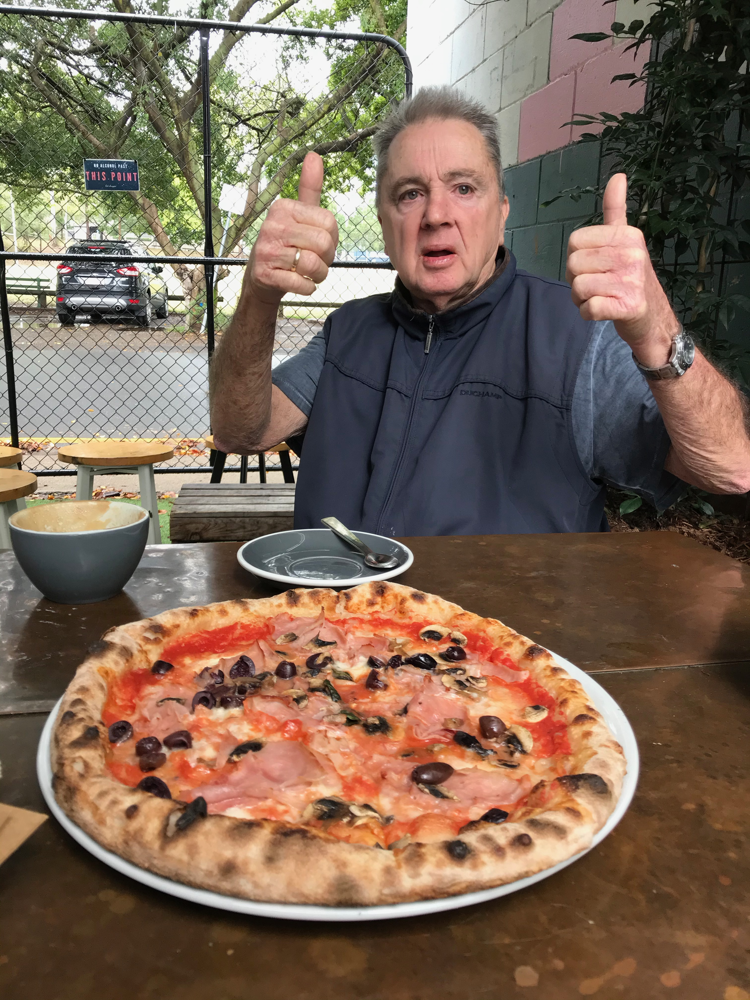

In [221]:
#MAKE A REQUEST TO DOWNLOAD A IMAGE FROM WEB (OR GET FROM THE DEVICE)
import requests
custom_image_path = data_path / "the trying image.jpg"
if not custom_image_path.is_file():
    with open(custom_image_path,"wb") as f :
        request = requests.get("https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/04-pizza-dad.jpeg")
        print(f"we are going to download the {custom_image_path} you puppy shit.....")
        f.write(request.content)
else:
    print(f"shut up you shit ({custom_image_path}) exist , not downloading......")


Image.open(custom_image_path,)

In [224]:
#READ THE IMAGE BY USING torchvision.io.read_image  WHICH WILL MAKE IT TO TENSOR
tuned_custom_image = torchvision.io.read_image(str(custom_image_path)).type(torch.float32)/255
#here we have also made the type as the default pytorch type (float32)
#and we also made the (/255) to make all of the numbers of the image tensor instad of being between 0 -> 255 to 0 -> 1 , to avoid the math exploding in the calculations

#make a transform to adjust the size
size_transform = transforms.Compose([transforms.Resize((64, 64))])
tuned_custom_image_transformed = size_transform(tuned_custom_image).to(device).unsqueeze(0)
#here we made it to device
#and also made the extra batch dimension to be able to make the model run


#--------------------------------------------------------------------------------------------------------------
#﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿ there is also another way that we used previously and it is even better
"""
img = Image.open(custom_image_path)
transformed_img = size_transform(img)

"""
# and here you dont have to deal with any problem


In [208]:
#make pred
model_4.eval()
with torch.inference_mode():
    preds = model_4(tuned_custom_image_transformed)

preds

tensor([[-0.3331,  0.1976, -0.7749]], device='cuda:0')

In [220]:
finale = class_names[torch.argmax(preds)]
finale

'steak'